# AIR IQ — Indian Air Quality Analysis

This notebook runs reproducible descriptive analysis on the original Kaggle `city_day.csv`. It does not create replacement observations. Place the file in `data/raw/city_day.csv` before running the data cells. All comparisons describe historical records, not current air quality.

In [2]:
import pandas as pd

df = pd.read_csv("../data/cleaned/city_day_cleaned.csv")

missing = pd.DataFrame({
    "Missing_Count": df.isnull().sum(),
    "Missing_Percentage": (df.isnull().mean() * 100).round(2)
})

missing = missing.sort_values(
    by="Missing_Percentage",
    ascending=False
)

print(missing)

            Missing_Count  Missing_Percentage
Xylene              18109               61.32
PM10                11140               37.72
NH3                 10328               34.97
Toluene              8041               27.23
Benzene              5623               19.04
AQI                  4681               15.85
AQI_Bucket           4681               15.85
PM2.5                4598               15.57
NOx                  4185               14.17
O3                   4022               13.62
SO2                  3854               13.05
NO2                  3585               12.14
NO                   3582               12.13
CO                   2059                6.97
Date                    0                0.00
City                    0                0.00


In [3]:
print("Both missing:",
      (df["AQI"].isnull() & df["AQI_Bucket"].isnull()).sum())

print("Only AQI missing:",
      (df["AQI"].isnull() & df["AQI_Bucket"].notnull()).sum())

print("Only AQI_Bucket missing:",
      (df["AQI"].notnull() & df["AQI_Bucket"].isnull()).sum())

Both missing: 4681
Only AQI missing: 0
Only AQI_Bucket missing: 0


In [4]:
print(df["AQI_Bucket"].value_counts())

print("\nAQI Statistics:")
print(df["AQI"].describe())

AQI_Bucket
Moderate        8829
Satisfactory    8224
Poor            2781
Very Poor       2337
Good            1341
Severe          1338
Name: count, dtype: int64

AQI Statistics:
count    24850.000000
mean       166.463581
std        140.696585
min         13.000000
25%         81.000000
50%        118.000000
75%        208.000000
max       2049.000000
Name: AQI, dtype: float64


## Setup and load

Install dependencies from `requirements.txt` in the project environment. The loader removes exact duplicate rows only, parses dates and numeric fields, and retains missing values and outliers.

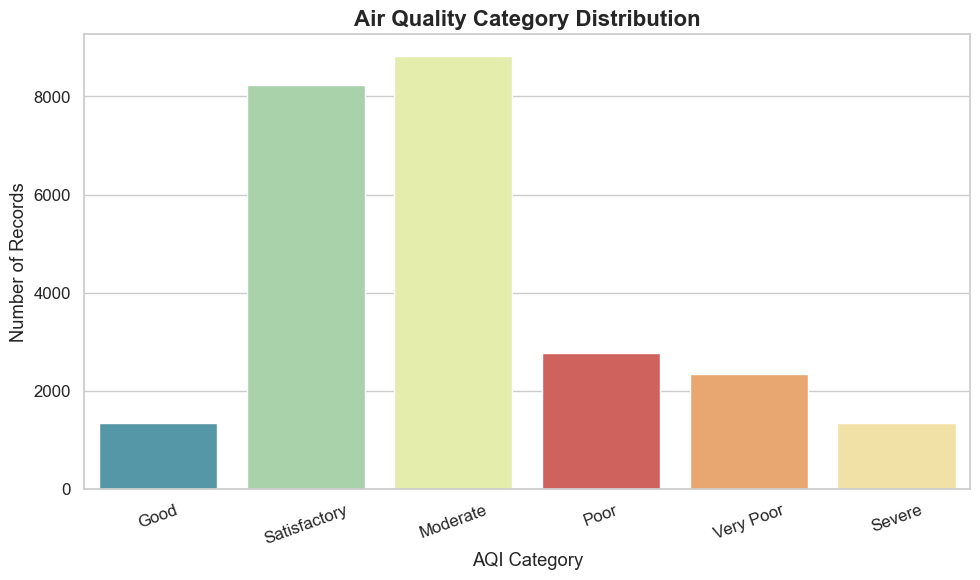

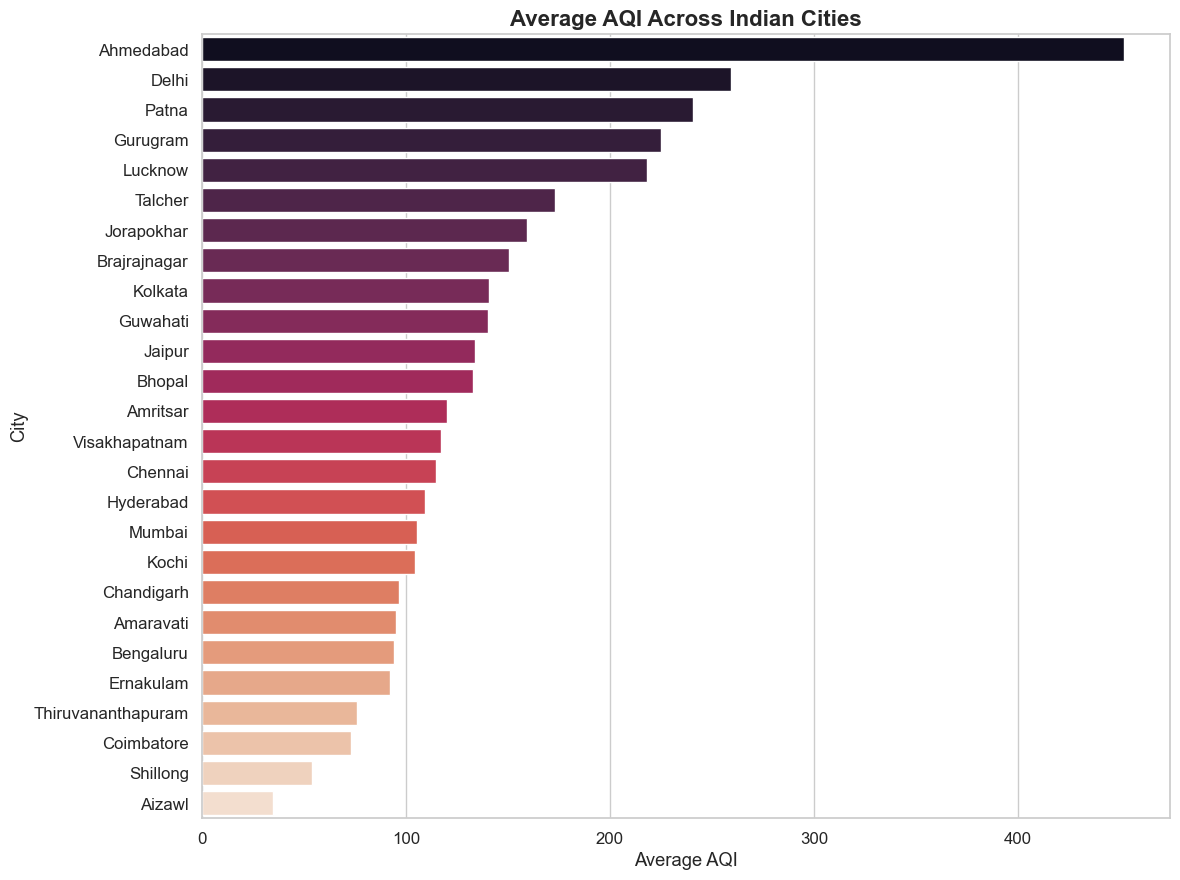

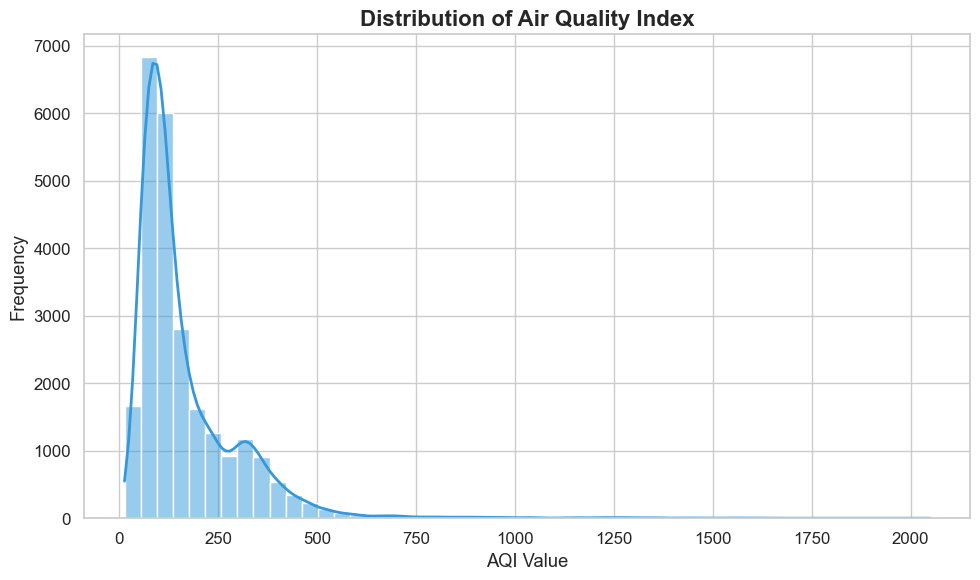

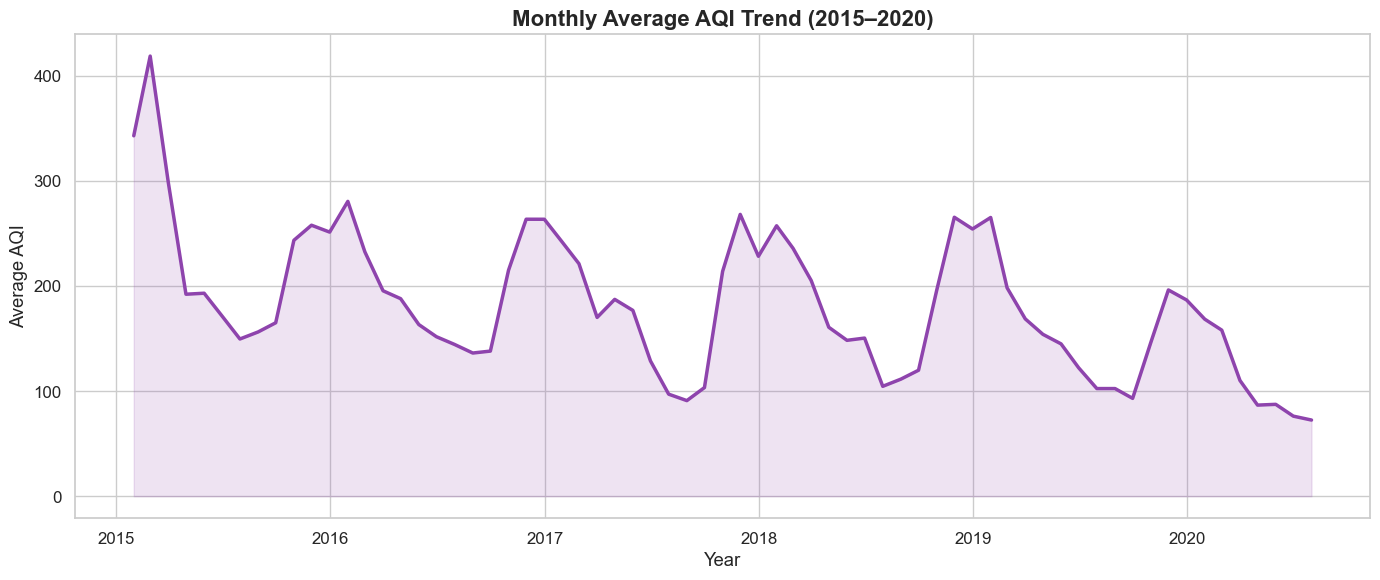

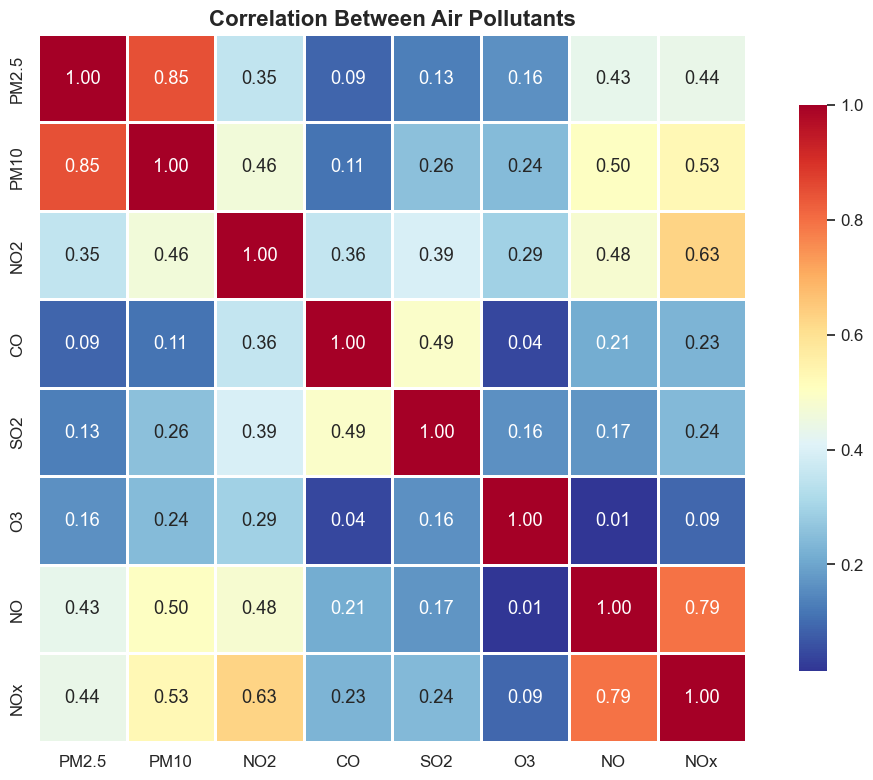

In [6]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Overall theme
sns.set_theme(style="whitegrid", context="notebook", font_scale=1.1)

# 1. AQI Category Distribution
plt.figure(figsize=(10, 6))
sns.countplot(
    data=df,
    x="AQI_Bucket",
    hue="AQI_Bucket",
    order=["Good", "Satisfactory", "Moderate", "Poor", "Very Poor", "Severe"],
    palette="Spectral",
    legend=False
)
plt.title("Air Quality Category Distribution", fontsize=16, weight="bold")
plt.xlabel("AQI Category")
plt.ylabel("Number of Records")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()


# 2. Average AQI by City
city_aqi = df.groupby("City")["AQI"].mean().sort_values(ascending=False)

plt.figure(figsize=(12, 9))
sns.barplot(
    x=city_aqi.values,
    y=city_aqi.index,
    hue=city_aqi.index,
    palette="rocket",
    legend=False
)
plt.title("Average AQI Across Indian Cities", fontsize=16, weight="bold")
plt.xlabel("Average AQI")
plt.ylabel("City")
plt.tight_layout()
plt.show()


# 3. AQI Distribution
plt.figure(figsize=(10, 6))
sns.histplot(
    data=df,
    x="AQI",
    bins=50,
    kde=True,
    color="#3498DB",
    edgecolor="white",
    line_kws={"linewidth": 2}
)
plt.title("Distribution of Air Quality Index", fontsize=16, weight="bold")
plt.xlabel("AQI Value")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()


# 4. Monthly AQI Trend
df["Date"] = pd.to_datetime(df["Date"])
monthly_aqi = df.set_index("Date")["AQI"].resample("ME").mean().dropna()

plt.figure(figsize=(14, 6))
sns.lineplot(
    x=monthly_aqi.index,
    y=monthly_aqi.values,
    color="#8E44AD",
    linewidth=2.5
)
plt.fill_between(
    monthly_aqi.index,
    monthly_aqi.values,
    alpha=0.15,
    color="#8E44AD"
)
plt.title("Monthly Average AQI Trend (2015–2020)", fontsize=16, weight="bold")
plt.xlabel("Year")
plt.ylabel("Average AQI")
plt.tight_layout()
plt.show()


# 5. Pollutant Correlation Heatmap
pollutants = ["PM2.5", "PM10", "NO2", "CO", "SO2", "O3", "NO", "NOx"]

plt.figure(figsize=(11, 8))
sns.heatmap(
    df[pollutants].corr(),
    annot=True,
    cmap="RdYlBu_r",
    fmt=".2f",
    linewidths=0.8,
    square=True,
    cbar_kws={"shrink": 0.8}
)
plt.title("Correlation Between Air Pollutants", fontsize=16, weight="bold")
plt.tight_layout()
plt.show()

In [ ]:
from src.data_cleaning import DEFAULT_INPUT, load_and_clean_data
from src.analysis import (
    aqi_category_counts, city_aqi_summary, missing_data_summary,
    monthly_aqi_trend, pollutant_correlations, pollutant_summary,
    seasonal_aqi_summary, yearly_aqi_trend,
)
from src.visualizations import (
    aqi_distribution_chart, category_chart, city_comparison_chart,
    correlation_heatmap, monthly_trend_chart, pm_scatter_chart,
    seasonal_chart, yearly_trend_chart,
)

data, cleaning_report = load_and_clean_data(DEFAULT_INPUT)
cleaning_report

## Data quality and coverage

Inspect missingness before interpreting any chart. Missing measurements are not imputed.

In [ ]:
missing_data_summary(data)

In [ ]:
data.describe(include="all").T

## AQI distribution, cities, and categories

In [ ]:
aqi_distribution_chart(data).show()
city_comparison_chart(data).show()
category_chart(data).show()
city_aqi_summary(data).head(10)

## Pollutants and relationships

Concentrations are in the units provided by the source. Pairwise Pearson correlation measures linear association only and does not establish cause.

In [ ]:
pollutant_summary(data)

In [ ]:
pm_scatter_chart(data).show()
correlation_heatmap(data).show()
pollutant_correlations(data)

## Monthly, seasonal, and yearly patterns

Trends pool available city-day records and are not population-weighted. Broad season groups are calendar-based: Winter (Dec–Feb), Summer (Mar–May), Monsoon (Jun–Sep), and Post-monsoon (Oct–Nov).

In [ ]:
monthly_aqi_trend(data).head()
monthly_trend_chart(data).show()

In [ ]:
seasonal_aqi_summary(data)
seasonal_chart(data).show()

In [ ]:
yearly_aqi_trend(data)
yearly_trend_chart(data).show()

## Interpretation checklist

- Compare city observation counts; unequal coverage can affect rankings.
- Means and maxima are sensitive to outliers; inspect medians and distributions too.
- AQI category counts use source-provided `AQI_Bucket` values only.
- Do not interpret correlation as causation or historical values as current AQI.
- Report findings only after executing the notebook on the downloaded source data.